# Time-of-flight LiDAR: link budget, sunlight and eye safety

A LiDAR (light detection and ranging) measures distances by timing light.
A **time-of-flight** (ToF) LiDAR sends a short laser pulse, a few
nanoseconds long, and stops a clock when the echo returns: a delay of
1 ns is 15 cm of range. Scanned over the scene, millions of such
measurements per second give the point clouds of self-driving cars,
survey drones and the depth sensor of a phone.

Whether a LiDAR sees a dark car at 200 m in full sunlight comes down to a
handful of numbers: how much of the pulse returns (the **link budget**),
how much sunlight the receiver sees at the same time, how well the
detector separates one from the other, and how much light the laser may
send without hurting an eye. This notebook goes through them with the
`lidar` module:

1. the LiDAR equation: the echo of a Lambertian target, and the weather,
2. sunlight: the background that sets the noise,
3. linear mode avalanche photodiodes: SNR, thresholds, detection
   probability and false alarms,
4. single photon avalanche diodes (SPADs): histograms, pile-up in
   sunlight and its correction,
5. eye safety: the class 1 limits at 905 and 1550 nm, pulse trains and
   scanned beams, and why long range LiDARs moved to 1550 nm.

The frequency modulated alternative follows in
notebook 131 (FMCW LiDAR), the scanners in
notebook 132 (beam scanning). The photometric background
(radiance, étendue) is that of notebook 105 (radiometry and photometry);
the APD noise model is the one of notebook 120 (fibre link).

In [1]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import lidar
from pyoptics import sketch

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()

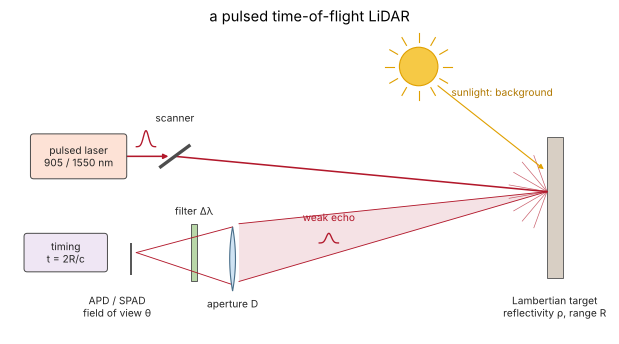

In [2]:
fig, ax = plt.subplots(figsize=(12, 5))
with sketch.text_scale(1.15):
    sketch.lidar_layout(ax, "tof", title="a pulsed time-of-flight LiDAR")
plt.show()

## 1. The LiDAR equation

A target that is larger than the laser spot and scatters diffusely
(Lambertian, reflectivity $\rho$) sends a fraction $\rho/\pi$ of the
incident power per steradian back along its normal. A receiver aperture
of diameter $D$ at the range $R$ subtends the solid angle
$\pi D^2/(4R^2)$, so

$$
P_r = P_t\,\frac{\rho\cos\theta}{\pi}\,\frac{\pi D^2/4}{R^2}\,T_\mathrm{atm}^2\,\eta_\mathrm{rx} ,
$$

independent of the beam divergence: a wider beam lights more of the
target, but each part of it less. The echo falls as $1/R^2$, not $1/R^4$
as for radar, because the target fills the beam. Small targets (a
pedestrian's leg at 300 m, a wire) are smaller than the spot and lose a
further factor of the area ratio.

Typical numbers: a 905 nm laser diode with 40 W peak in 5 ns (0.2 µJ),
or a 1550 nm fibre laser with 400 W (2 µJ; why it may send ten times
more follows in section 5); a 25 mm receiver aperture with 80 %
transmission; a dark car of 10 % reflectivity.

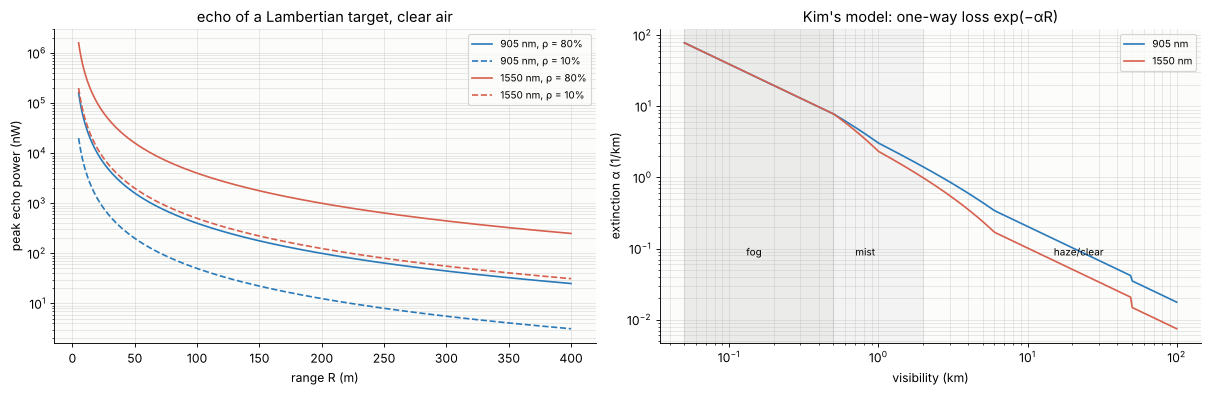

905 nm: echo energy at 200 m, rho = 10 %: 6.25e-17 J = 285 photons (of 9.1e+11 sent)
1550 nm: echo energy at 200 m, rho = 10 %: 6.25e-16 J = 4877 photons (of 1.6e+13 sent)
visibility 20.0 km: two-way transmission over 100 m: 0.98 (905 nm), 0.99 (1550 nm)
visibility  1.0 km: two-way transmission over 100 m: 0.54 (905 nm), 0.63 (1550 nm)
visibility  0.2 km: two-way transmission over 100 m: 0.02 (905 nm), 0.02 (1550 nm)


In [3]:
D_RX, ETA_RX = 0.025, 0.8          # receiver aperture (m) and transmission
T_P = 5e-9                         # pulse duration (s)
SYSTEMS = {905: dict(E=0.2e-6, filter_nm=25.0, R_d=0.55, k_A=0.02, M=100, color=BLUE,
                     name="905 nm, Si APD"),
           1550: dict(E=2e-6, filter_nm=3.0, R_d=1.0, k_A=0.5, M=10, color=RED,
                      name="1550 nm, InGaAs APD")}
R = np.linspace(5, 400, 400)

fig, axs = plt.subplots(1, 2, figsize=(15, 4.8), layout="constrained")
for lam, s in SYSTEMS.items():
    for rho, ls in ((0.8, "-"), (0.1, "--")):
        P = lidar.lambertian_return(s["E"]/T_P, R, rho, D_RX, efficiency=ETA_RX)
        axs[0].semilogy(R, P*1e9, color=s["color"], ls=ls,
                        label="{}, ρ = {:.0%}".format(s["name"].split(",")[0], rho))
axs[0].set_xlabel("range R (m)")
axs[0].set_ylabel("peak echo power (nW)")
axs[0].set_title("echo of a Lambertian target, clear air")
axs[0].legend(fontsize=9)
axs[0].grid(alpha=0.3, which="both")

vis = np.logspace(-1.3, 2, 300)
for lam, s in SYSTEMS.items():
    a = lidar.extinction_coefficient(vis, lam)
    axs[1].loglog(vis, a, color=s["color"], label="{} nm".format(lam))
axs[1].axvspan(0.05, 0.5, color=GREY, alpha=0.12)
axs[1].axvspan(0.5, 2, color=GREY, alpha=0.06)
axs[1].text(0.13, 0.08, "fog", fontsize=9)
axs[1].text(0.7, 0.08, "mist", fontsize=9)
axs[1].text(15, 0.08, "haze/clear", fontsize=9)
axs[1].set_xlabel("visibility (km)")
axs[1].set_ylabel("extinction α (1/km)")
axs[1].set_title("Kim's model: one-way loss exp(−αR)")
axs[1].legend(fontsize=9)
axs[1].grid(alpha=0.3, which="both")
plt.show()

for lam, s in SYSTEMS.items():
    P200 = lidar.lambertian_return(s["E"], 200.0, 0.1, D_RX, efficiency=ETA_RX)
    print("{} nm: echo energy at 200 m, rho = 10 %: {:.2e} J = {:.0f} photons "
          "(of {:.1e} sent)".format(lam, P200, lidar.photons(P200, lam), lidar.photons(s["E"], lam)))
for V in (20.0, 1.0, 0.2):
    a = lidar.extinction_coefficient(V, np.array([905, 1550]))
    T2 = np.exp(-2*a*0.1)
    print("visibility {:4.1f} km: two-way transmission over 100 m: {:.2f} (905 nm), "
          "{:.2f} (1550 nm)".format(V, *T2))

Of the $10^{12}$ to $10^{13}$ photons of a pulse, a few hundred to a few
thousand come back from a dark car at 200 m: the receiver has to find
them within a few nanoseconds. The echo of 13 nW peak at 905 nm and 125 nW
at 1550 nm is the ten times larger pulse energy, nothing else.

Haze costs little over 100 m. The two wavelengths differ in haze (the
aerosol extinction falls with the wavelength), but in fog, whose droplets
are much larger than either wavelength, both suffer alike: Kim's model
removes the wavelength dependence below 0.5 km visibility, and a fog of
200 m visibility takes 98 % of the light over 100 m and back. Rain and
spray on the cover glass are the other everyday losses. (Water absorbs
more at 1550 nm than at 905 nm, which matters for a wet window, not for
the drops in the air.)

## 2. Sunlight

The Sun lights the same target as the laser. The direct solar spectrum on
the ground (AM1.5) peaks near 500 nm at about 1.3 W m⁻² nm⁻¹; at 905 nm it
is still 0.8, at 1550 nm about 0.22 W m⁻² nm⁻¹. The receiver sees the
part of the sunlit target inside the field of view $\theta$ of one
detector and the passband $\Delta\lambda$ of its filter:

$$
P_\mathrm{bg} = E_\odot(\lambda)\,\Delta\lambda\;\frac{\rho}{\pi}\;\frac{\pi D^2}{4}\,\Omega_\mathrm{fov}\,\eta_\mathrm{rx} ,
\qquad \Omega_\mathrm{fov}\approx \frac{\pi\theta^2}{4} ,
$$

independent of the range (a farther target fills the same field of view
with more area). The product $A\Omega$ is the étendue of one detector
(notebook 83, étendue): it collects both signal and background, but the
signal only through $A$. Narrow filters and small fields of view are the
levers. A 905 nm diode laser drifts by 0.25 nm/K and needs a filter of
20 to 30 nm over the automotive temperature range; a 1550 nm fibre laser
is stable and allows 1 to 3 nm.

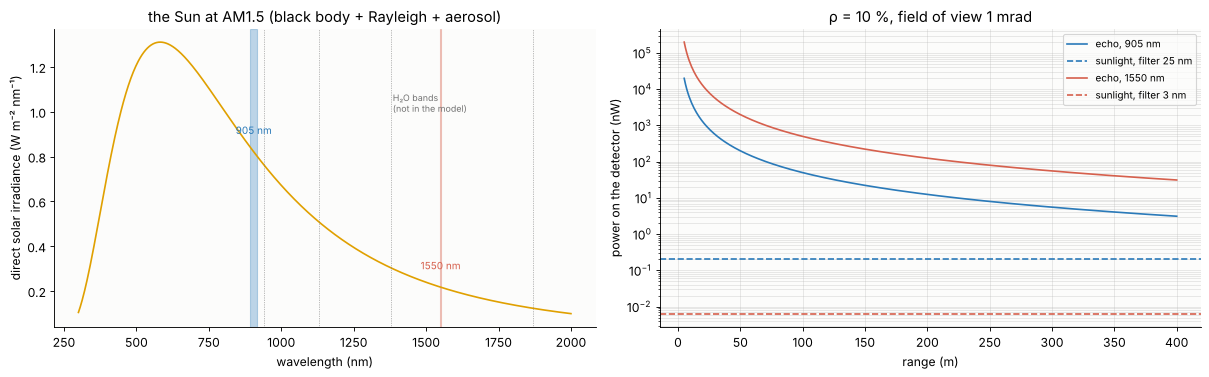

905 nm: sunlight on the detector 2.02e-10 W = 9.18e+08 photons/s = 4.6 photons per 5 ns
1550 nm: sunlight on the detector 6.40e-12 W = 4.99e+07 photons/s = 0.2 photons per 5 ns


In [4]:
lam = np.linspace(300, 2000, 800)
E_sun = lidar.solar_irradiance(lam)
FOV = 1e-3

fig, axs = plt.subplots(1, 2, figsize=(15, 4.6), layout="constrained")
axs[0].plot(lam, E_sun, color=ORANGE)
for l0, s in SYSTEMS.items():
    axs[0].axvspan(l0 - s["filter_nm"]/2, l0 + s["filter_nm"]/2, color=s["color"], alpha=0.3)
    axs[0].text(l0, lidar.solar_irradiance(l0) + 0.08, "{} nm".format(l0), ha="center",
                color=s["color"], fontsize=9)
for lb in (940, 1130, 1380, 1870):
    axs[0].axvline(lb, color=GREY, lw=0.6, ls=":")
axs[0].text(1385, 1.0, "H₂O bands\n(not in the model)", fontsize=8, color=GREY)
axs[0].set_xlabel("wavelength (nm)")
axs[0].set_ylabel("direct solar irradiance (W m⁻² nm⁻¹)")
axs[0].set_title("the Sun at AM1.5 (black body + Rayleigh + aerosol)")

R = np.linspace(5, 400, 400)
for l0, s in SYSTEMS.items():
    Pbg = lidar.background_power(lidar.solar_irradiance(l0), 0.1, D_RX, FOV, s["filter_nm"], ETA_RX)
    Ps = lidar.lambertian_return(s["E"]/T_P, R, 0.1, D_RX, efficiency=ETA_RX)
    axs[1].semilogy(R, Ps*1e9, color=s["color"], label="echo, " + s["name"].split(",")[0])
    axs[1].axhline(Pbg*1e9, color=s["color"], ls="--", label="sunlight, filter {:.0f} nm".format(
        s["filter_nm"]))
axs[1].set_xlabel("range (m)")
axs[1].set_ylabel("power on the detector (nW)")
axs[1].set_title("ρ = 10 %, field of view 1 mrad")
axs[1].legend(fontsize=9)
axs[1].grid(alpha=0.3, which="both")
plt.show()

for l0, s in SYSTEMS.items():
    Pbg = lidar.background_power(lidar.solar_irradiance(l0), 0.1, D_RX, FOV, s["filter_nm"], ETA_RX)
    print("{} nm: sunlight on the detector {:.2e} W = {:.2e} photons/s = {:.1f} photons per "
          "5 ns".format(l0, Pbg, lidar.photons(Pbg, l0), lidar.photons(Pbg*T_P, l0)))

The sunlight is a steady power, below 1 nW for a 1 mrad field of view,
much less than the echo's peak power even at 400 m. That looks
harmless, but the background is not compared with the echo, it is the
**shot noise** of the background that competes with the echo, and in a
photon counter that sees single photons it fills every time bin
(section 4). The 1550 nm receiver sees 30 times less sunlight: four times
less solar irradiance and an eight times narrower filter.

## 3. Linear mode avalanche photodiodes

An avalanche photodiode multiplies each photoelectron by the gain $M$,
with an excess noise $F(M) = k_A M + (1-k_A)(2-1/M)$ (McIntyre); a
transimpedance amplifier adds its input noise $i_n$. For a pulse of peak
power $P_s$ on a background $P_\mathrm{bg}$, in the noise bandwidth $B$,

$$
\mathrm{SNR} = \frac{M R_d P_s}{\sqrt{2q M^2 F\,\left(R_d(P_s + P_\mathrm{bg}) + I_d\right)B + i_n^2 B}} .
$$

Silicon APDs at 905 nm have a small ionization ratio, $k_A \approx 0.02$,
and work at gains of 100 or more; InGaAs APDs at 1550 nm ($k_A \approx
0.5$) are noisier and are best near $M = 10$. The amplifier noise is
3 pA/√Hz, the bandwidth 100 MHz for 5 ns pulses.

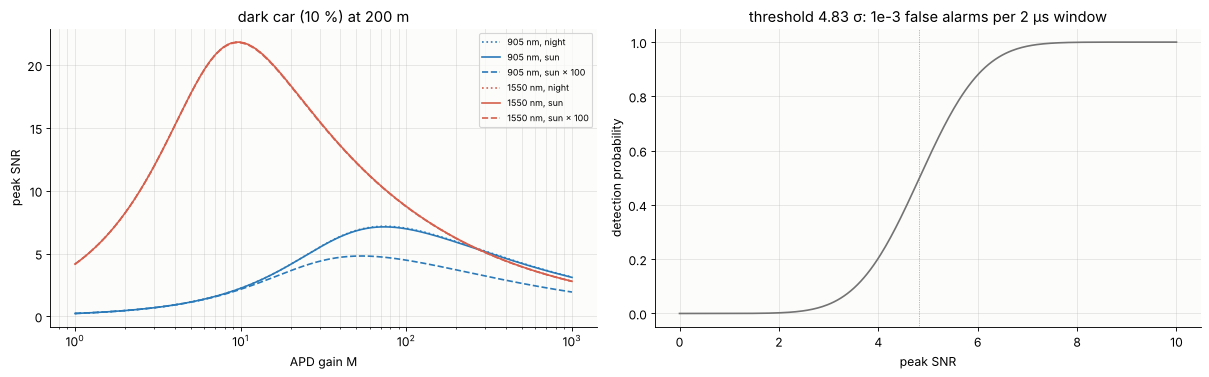

threshold: 4.83 sigma; false alarm rate 500 per second


In [5]:
B, I_N = 1e8, 3e-12
M = np.logspace(0, 3, 300)
fig, axs = plt.subplots(1, 2, figsize=(15, 4.6), layout="constrained")
for l0, s in SYSTEMS.items():
    Pbg = lidar.background_power(lidar.solar_irradiance(l0), 0.1, D_RX, FOV, s["filter_nm"], ETA_RX)
    Ps = lidar.lambertian_return(s["E"]/T_P, 200.0, 0.1, D_RX, efficiency=ETA_RX)
    for bg, ls in ((0.0, ":"), (Pbg, "-"), (100*Pbg, "--")):
        snr = lidar.apd_snr(Ps, B, s["R_d"], M, s["k_A"], bg, input_noise=I_N)
        axs[0].semilogx(M, snr, color=s["color"], ls=ls,
                        label="{} nm, {}".format(l0, {0: "night", 1: "sun", 2: "sun × 100"}[[0.0, Pbg, 100*Pbg].index(bg)]))
axs[0].set_xlabel("APD gain M")
axs[0].set_ylabel("peak SNR")
axs[0].set_title("dark car (10 %) at 200 m")
axs[0].legend(fontsize=8)
axs[0].grid(alpha=0.3, which="both")

# threshold for 1e-3 false alarms per 2 us listening window
window = 2*300/lidar.C
T_thr = np.sqrt(2*np.log(B/np.sqrt(3)/(1e-3/window)))
snr_axis = np.linspace(0, 10, 300)
axs[1].plot(snr_axis, lidar.detection_probability(snr_axis, T_thr), color=GREY)
axs[1].axvline(T_thr, color=GREY, lw=0.6, ls=":")
axs[1].set_xlabel("peak SNR")
axs[1].set_ylabel("detection probability")
axs[1].set_title("threshold {:.2f} σ: 1e-3 false alarms per 2 µs window".format(T_thr))
axs[1].grid(alpha=0.3)
plt.show()
print("threshold: {:.2f} sigma; false alarm rate {:.0f} per second".format(
    T_thr, lidar.false_alarm_rate(T_thr, B)))

Both receivers have an optimum gain: below it the amplifier noise
dominates, above it the excess noise of the avalanche multiplies the
shot noise faster than the signal. For the InGaAs APD the optimum is
near $M = 10$, for the silicon APD with its small $k_A$ near 80. With a
1 mrad field of view, the sunlight hardly matters for a linear APD: the
curves for night and sun coincide, because the shot noise of the echo
itself and the amplifier noise dominate. A 100 times larger background,
as in a flash LiDAR whose pixels see 10 mrad each, lowers the
optimum gain and costs the 905 nm receiver 15 % of its SNR.

A threshold detector must also not fire on noise. Rice's formula gives
the rate at which Gaussian noise of bandwidth $B$ crosses a level $T$
(in units of the rms noise), $B/\sqrt{3}\,e^{-T^2/2}$. Allowing one false
alarm in a thousand 2 µs listening windows (300 m) needs a threshold of
4.8 σ; a pulse is then detected with 99 % probability at an SNR of 7.2.
(The SNR is the signal over the noise at the peak; averaging or matched
filtering of several pulses raises it, at the price of frame rate.)

The maximum range follows: where the SNR of a given target drops to 7.2.

905 nm, rho = 10%: 99 % detection up to 196 m
905 nm, rho = 80%: 99 % detection up to 531 m
1550 nm, rho = 10%: 99 % detection up to 432 m
1550 nm, rho = 80%: 99 % detection up to inf m


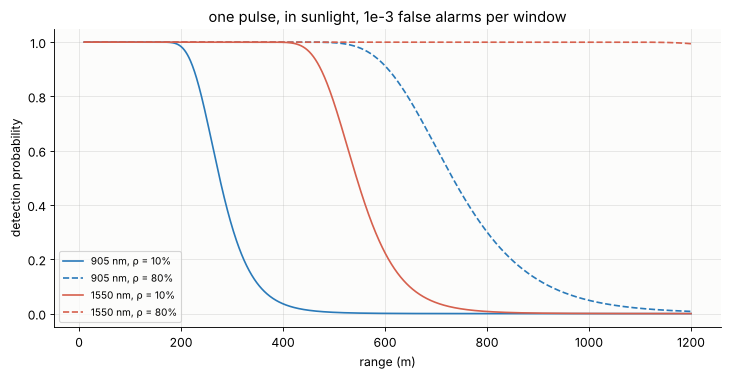

In [6]:
R = np.linspace(10, 1200, 1200)
fig, ax = plt.subplots(figsize=(9, 4.6), layout="constrained")
for l0, s in SYSTEMS.items():
    Pbg = lidar.background_power(lidar.solar_irradiance(l0), 0.1, D_RX, FOV, s["filter_nm"], ETA_RX)
    for rho, ls in ((0.1, "-"), (0.8, "--")):
        Ps = lidar.lambertian_return(s["E"]/T_P, R, rho, D_RX, efficiency=ETA_RX)
        snr = lidar.apd_snr(Ps, B, s["R_d"], s["M"], s["k_A"], Pbg*rho/0.1, input_noise=I_N)
        Pd = lidar.detection_probability(snr, T_thr)
        ax.plot(R, Pd, color=s["color"], ls=ls, label="{} nm, ρ = {:.0%}".format(l0, rho))
        print("{} nm, rho = {:.0%}: 99 % detection up to {:.0f} m".format(
            l0, rho, R[np.argmax(Pd < 0.99)] if np.any(Pd < 0.99) else np.inf))
ax.set_xlabel("range (m)")
ax.set_ylabel("detection probability")
ax.set_title("one pulse, in sunlight, 1e-3 false alarms per window")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
plt.show()

With these (typical) numbers the 905 nm LiDAR detects a dark car to about
200 m and a white one to about 530 m; the 1550 nm LiDAR with its ten times
larger pulse reaches a dark car at 430 m, roughly twice as far (its APD
is noisier). Range scales as the square
root of the pulse energy times the receiver area (at fixed SNR),
so a factor of two in range costs four in energy or aperture.

## 4. Single photon avalanche diodes

A SPAD is an APD biased above breakdown: a single photon triggers a
self-sustaining avalanche, a digital pulse, and the diode is dead until
it is quenched (a few to tens of nanoseconds). Arrays of SPADs in
standard CMOS are cheap, and they make flash LiDARs and phone depth
sensors possible. A SPAD does not measure the echo's amplitude: it counts
photons into time bins over many laser shots and builds a histogram, in
which the echo is a peak on the flat background of sunlight and dark
counts.

With a dead time longer than the listening window, a SPAD registers at
most the **first** photon of each shot. Under strong background light the
first photon usually arrives before the echo, and the histogram decays
along the window: **pile-up**. Coates' formula gives the probability that
the first detection falls into bin $i$,

$$
p_i = \left(1 - e^{-n_i}\right)\exp\Big(-\sum_{j<i} n_j\Big) ,
$$

for mean photon numbers $n_i$ per bin and shot, and inverts it,
$n_i = -\ln\big(1 - h_i/(N - \sum_{j<i}h_j)\big)$ for $h_i$ counts in $N$
shots. Below a simulated SPAD with 0.5 ns bins over a 1 µs window and a
target at 100 m, in shade and in full sun.

night: 0.02 background photons/µs   :  1.33% of shots see a background photon before the echo; 1645 shots left at the echo; correction valid to 150 m
shade: 1 background photon/µs       : 48.68% of shots see a background photon before the echo;  854 shots left at the echo; correction valid to 150 m
full sun: 20 background photons/µs  : 100.00% of shots see a background photon before the echo;    0 shots left at the echo; correction valid to 35 m


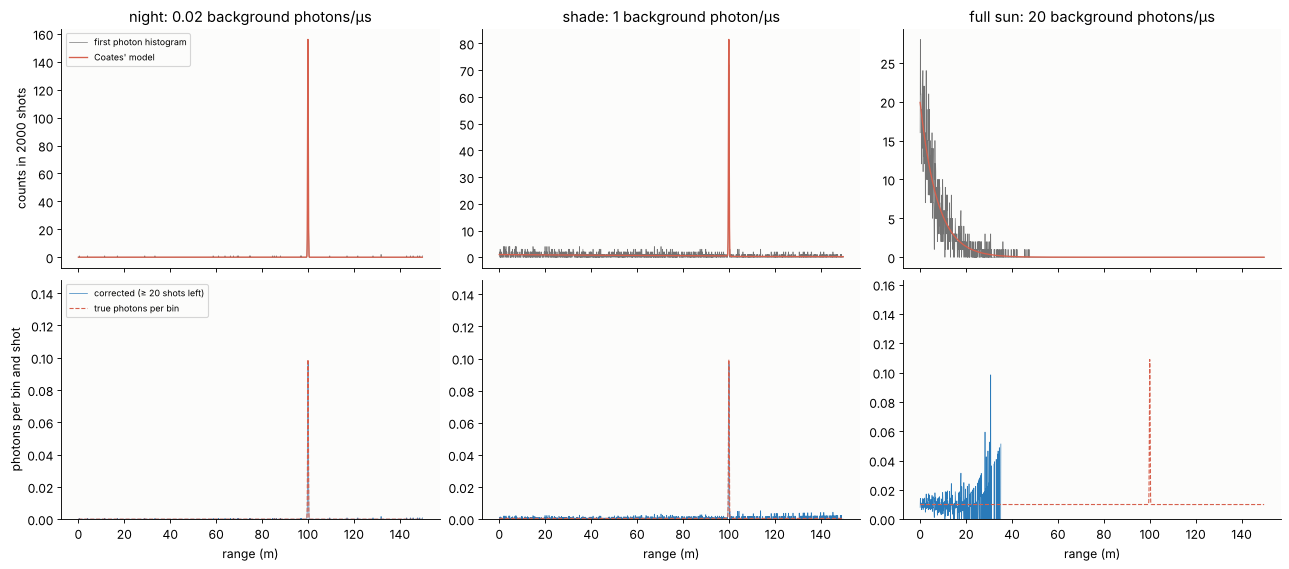

In [7]:
rng = np.random.default_rng(1)
BIN = 0.5e-9
t_bins = np.arange(2000)*BIN
r_bins = t_bins*lidar.C/2
R_T = 100.0
sig = np.exp(-0.5*((t_bins - 2*R_T/lidar.C)/(1.0e-9))**2)
sig *= 0.5/sig.sum()                         # 0.5 detected signal photons per shot
i_echo = np.argmax(sig)
N_SHOTS = 2000
CASES = ((1e-5, "night: 0.02 background photons/µs"),
         (5e-4, "shade: 1 background photon/µs"),
         (1e-2, "full sun: 20 background photons/µs"))

fig, axs = plt.subplots(2, 3, figsize=(16, 7), layout="constrained", sharex=True)
for k, (bg, name) in enumerate(CASES):
    n = sig + bg
    counts = rng.poisson(n, size=(N_SHOTS, len(n)))
    first = np.argmax(counts > 0, axis=1)[counts.any(axis=1)]
    h = np.bincount(first, minlength=len(n)).astype(float)
    axs[0, k].plot(r_bins, h, color=GREY, lw=0.6, label="first photon histogram")
    axs[0, k].plot(r_bins, N_SHOTS*lidar.coates_histogram(n), color=RED, lw=1.2,
                   label="Coates' model")
    axs[0, k].set_title(name)
    remaining = N_SHOTS - (np.cumsum(h) - h)
    n_hat = np.where(remaining >= 20, lidar.coates_correction(h, N_SHOTS), np.nan)
    axs[1, k].plot(r_bins, n_hat, color=BLUE, lw=0.6, label="corrected (≥ 20 shots left)")
    axs[1, k].plot(r_bins, n, color=RED, lw=1.0, ls="--", label="true photons per bin")
    axs[1, k].set_xlabel("range (m)")
    axs[1, k].set_ylim(0, 1.5*n.max())
    ok = np.isfinite(n_hat)
    print("{:36s}: {:6.2%} of shots see a background photon before the echo; "
          "{:4d} shots left at the echo; correction valid to {:.0f} m".format(
              name, -np.expm1(-bg*i_echo), int(remaining[i_echo]), r_bins[ok][-1]))
axs[0, 0].set_ylabel("counts in {} shots".format(N_SHOTS))
axs[1, 0].set_ylabel("photons per bin and shot")
axs[0, 0].legend(fontsize=8, loc="upper left")
axs[1, 0].legend(fontsize=8, loc="upper left")
plt.show()

At night the histogram is the echo on an empty background. In shade,
half of the shots have registered a background photon before the echo
returns from 100 m, the background decays along the window and the
echo is half as high as it should be (grey: simulation, red: Coates'
model). Coates' correction (bottom) restores the flat background and the
true height of the echo, with noise that grows along the window as the
number of shots still listening falls. In full sun, practically every
shot ends on a background photon within the first 40 m: no shot is left
to see the echo at 100 m, and no correction can create information that
the dead SPAD never recorded. Real SPAD LiDARs fight pile-up with
shorter windows (gating), attenuating the background, several SPADs per
pixel combined in coincidence, and short dead times.

How precisely does the histogram give the range? The echo's centroid is
an average over the detected signal photons: its error falls as
$\sigma_t/\sqrt{N_s}$, the pulse width (and the timing jitter of the SPAD)
over the root of the number of signal photons, as long as the
background is small.

background 1e-05: echo missed in 1, 0, 0, 0, 0, 0 of 60 trials for 10, 30, 100, 300, 1000, 3000 shots


background 0.0005: echo missed in 33, 2, 0, 0, 0, 0 of 60 trials for 10, 30, 100, 300, 1000, 3000 shots


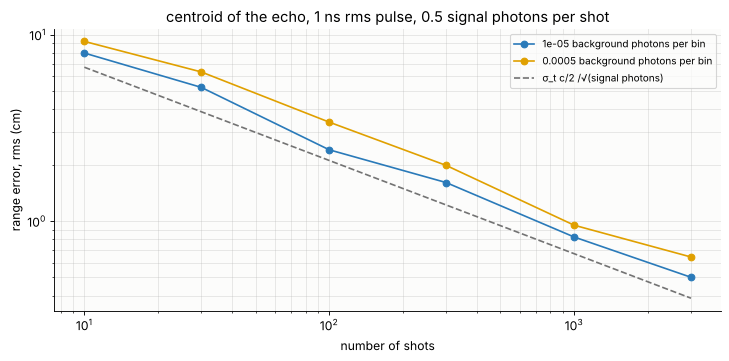

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.4), layout="constrained")
sigma_t = 1.0e-9
Ns = np.array([10, 30, 100, 300, 1000, 3000])
for bg, c in ((1e-5, BLUE), (5e-4, ORANGE)):
    rms, miss = [], []
    for N in Ns:
        e = []
        for trial in range(60):
            counts = rng.poisson(sig + bg, size=(N, len(sig)))
            first = np.argmax(counts > 0, axis=1)[counts.any(axis=1)]
            h = np.bincount(first, minlength=len(sig)).astype(float)
            n_hat = np.nan_to_num(lidar.coates_correction(h, N))
            i0 = np.argmax(np.convolve(n_hat, np.ones(7), "same"))
            sl = slice(max(i0 - 8, 0), i0 + 9)
            w = n_hat[sl] - bg
            e.append(np.sum(w*r_bins[sl])/np.sum(w) - R_T)
        e = np.array(e)
        good = np.abs(e) < 1.0
        miss.append(1 - good.mean())
        rms.append(np.sqrt(np.mean(e[good]**2)) if good.any() else np.nan)
    ax.loglog(Ns, np.array(rms)*100, "o-", color=c,
              label="{:g} background photons per bin".format(bg))
    print("background {:g}: echo missed in {} of 60 trials for {} shots".format(
        bg, ", ".join("{:.0f}".format(60*m) for m in miss), ", ".join(str(N) for N in Ns)))
ax.loglog(Ns, sigma_t*lidar.C/2/np.sqrt(Ns*0.5)*100, color=GREY, ls="--",
          label="σ_t c/2 /√(signal photons)")
ax.set_xlabel("number of shots")
ax.set_ylabel("range error, rms (cm)")
ax.set_title("centroid of the echo, 1 ns rms pulse, 0.5 signal photons per shot")
ax.legend(fontsize=9)
ax.grid(alpha=0.3, which="both")
plt.show()

Without background, the range error follows the photon statistics: 15 cm
of pulse width (1 ns rms) averaged over 500 signal photons gives 7 mm.
With a background, the centroid is pulled by background counts under the
peak and the error stays higher, and with few shots the echo is
sometimes not found at all (the misses are left out of the rms). Photon counting trades the
amplitude of a linear APD for many shots; the time to collect them is
part of the frame time budget of a scanning LiDAR.

## 5. Eye safety

LiDARs for cars must be **class 1**: safe under all reasonably
foreseeable conditions, including staring into the beam with optical
instruments. IEC 60825-1 sets accessible emission limits (AELs) for the
energy that passes a measurement aperture at the closest point of
access (7 mm, the dark adapted pupil, for wavelengths that reach the
retina, 400 to 1400 nm; 1 to 3.5 mm beyond, where the cornea and lens
absorb).

Between 400 and 1400 nm the eye focuses the beam onto the retina, a
gain in irradiance of about $10^5$. At 1550 nm the water of the cornea
and the lens absorbs the light before it reaches the retina, and the
limits are three to four orders of magnitude higher. Below the class 1
AEL against the exposure duration (from `lidar.ael_class1()`, the 2014
edition for a point source), and in the right panel as a peak power for a
single pulse.

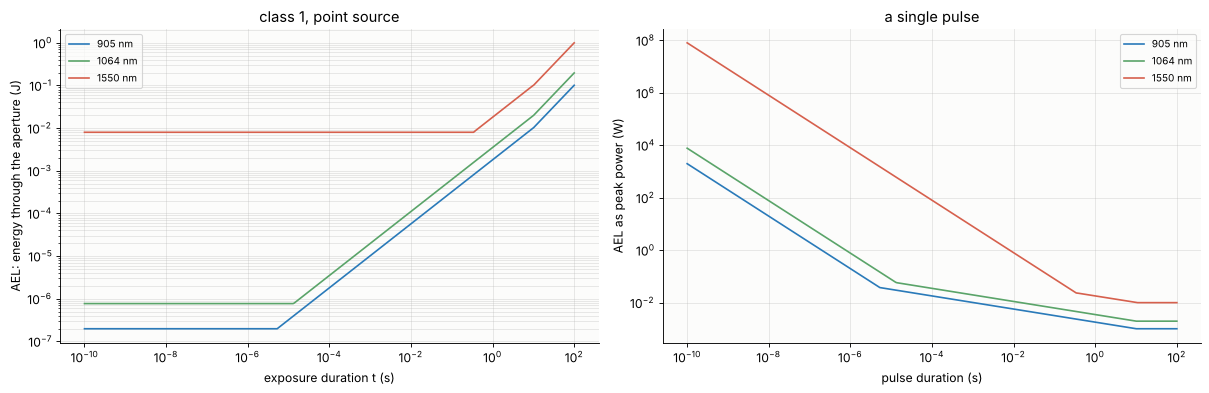

905 nm: single 5 ns pulse 1.98e-07 J, continuous (100 s) 1.01e-03 W
1550 nm: single 5 ns pulse 8.00e-03 J, continuous (100 s) 1.00e-02 W


In [9]:
t = np.logspace(-10, 2, 400)
fig, axs = plt.subplots(1, 2, figsize=(15, 4.8), layout="constrained")
for l0, c in ((905, BLUE), (1064, GREEN), (1550, RED)):
    E = lidar.ael_class1(l0, t)
    axs[0].loglog(t, E, color=c, label="{} nm".format(l0))
    axs[1].loglog(t, E/t, color=c, label="{} nm".format(l0))
axs[0].set_xlabel("exposure duration t (s)")
axs[0].set_ylabel("AEL: energy through the aperture (J)")
axs[0].set_title("class 1, point source")
axs[1].set_xlabel("pulse duration (s)")
axs[1].set_ylabel("AEL as peak power (W)")
axs[1].set_title("a single pulse")
for ax in axs:
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3, which="both")
plt.show()
for l0 in (905, 1550):
    print("{} nm: single 5 ns pulse {:.2e} J, continuous (100 s) {:.2e} W".format(
        l0, lidar.ael_class1(l0, 5e-9), lidar.ael_class1(l0, 100.0)/100))

A single 5 ns pulse may carry 0.2 µJ at 905 nm but 8 mJ at 1550 nm,
40 000 times more; for long exposures the ratio is 10 (1 mW against
10 mW). A LiDAR sends many pulses, and the standard has three rules for
pulse trains: every single pulse must be below the single pulse limit;
the average power over the time base (100 s for class 1) must be below
the limit for that time; and between 400 and 1400 nm every pulse must be
below the single pulse limit times $C_5 = N^{-1/4}$, $N$ the number of
pulses within $T_2 = 10$ s (a conservative form of this rule:
the 2014 edition relaxes it for small sources). `class1_pulse_energy()`
returns the most restrictive one.

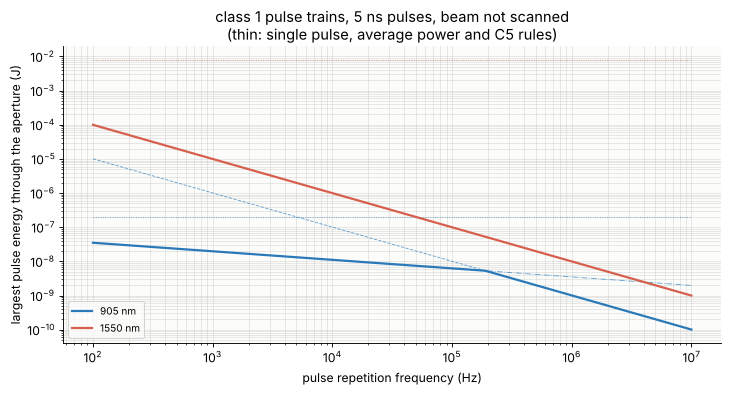

PRF 1e+04 Hz: 1.1e-08 J at 905 nm, 1.0e-06 J at 1550 nm
PRF 1e+06 Hz: 1.0e-09 J at 905 nm, 1.0e-08 J at 1550 nm


In [10]:
prf = np.logspace(2, 7, 300)
fig, ax = plt.subplots(figsize=(9, 4.8), layout="constrained")
for l0, c in ((905, BLUE), (1550, RED)):
    rules = np.array([list(lidar.class1_pulse_energy(l0, 5e-9, f, return_rules=True)[1].values())
                      for f in prf])
    E = rules.min(axis=1)
    ax.loglog(prf, E, color=c, lw=2, label="{} nm".format(l0))
    for k, (name, ls) in enumerate((("single pulse", ":"), ("average power", "--"),
                                    ("C5 = N^-1/4", "-."))):
        if np.all(np.isfinite(rules[:, k])):
            ax.loglog(prf, rules[:, k], color=c, lw=0.8, ls=ls, alpha=0.7)
ax.set_xlabel("pulse repetition frequency (Hz)")
ax.set_ylabel("largest pulse energy through the aperture (J)")
ax.set_title("class 1 pulse trains, 5 ns pulses, beam not scanned\n"
             "(thin: single pulse, average power and C5 rules)")
ax.legend(fontsize=9)
ax.grid(alpha=0.3, which="both")
plt.show()
for f in (1e4, 1e6):
    print("PRF {:.0e} Hz: {:.1e} J at 905 nm, {:.1e} J at 1550 nm".format(
        f, lidar.class1_pulse_energy(905, 5e-9, f), lidar.class1_pulse_energy(1550, 5e-9, f)))

A beam that is not scanned and fires a million pulses per second may
carry only 1 nJ per pulse at 905 nm (the average power rule, 1 mW over
1 MHz), 200 times less than the 0.2 µJ of section 1. A real LiDAR scans:
the beam crosses a given pupil only briefly. Take a spinning LiDAR that
rotates 10 times per second, with a beam of 20 mm diameter at its window
and 20 kHz pulse rate per beam. At the closest point of access, 100 mm
from the axis, the beam sweeps across the measurement aperture in a few
milliseconds, with about 90 pulses per pass and 100 passes in the 10 s
of $T_2$. Each rule then reads: a single pulse; one pass as one
exposure of its duration; the $C_5$ reduction for all pulses within
$T_2$; and the average power, with the time base of 100 s reduced to the
time the beam actually spends in the aperture. Each limit applies to the
energy through the aperture, so the emitted energy may be larger by the
inverse of the fraction of the beam that the aperture passes.

In [11]:
D_BEAM, D_ACCESS = 20e-3, 0.1        # beam diameter at the window, closest point of access
ROT, PRF = 10.0, 20e3                # rotations per second, pulses per second per beam
v_beam = 2*np.pi*D_ACCESS*ROT        # speed of the beam across the aperture (m/s)
for l0 in (905, 1550):
    a_short = lidar.measurement_aperture(l0, 1e-3)
    dwell = (D_BEAM + a_short)/v_beam
    n_pass = dwell*PRF
    N_T2 = n_pass*10*ROT
    t_exp = dwell*100*ROT                                   # time in the aperture in 100 s
    frac = lambda t: lidar.aperture_fraction(D_BEAM, lidar.measurement_aperture(l0, t))
    limits = {"single pulse": lidar.ael_class1(l0, T_P)/frac(T_P),
              "one pass": lidar.ael_class1(l0, dwell)/n_pass/frac(dwell),
              "C5 = N^-1/4": (lidar.ael_class1(l0, T_P)*N_T2**-0.25/frac(T_P) if l0 <= 1400
                              else np.inf),
              "average": lidar.ael_class1(l0, t_exp)/(n_pass*100*ROT)/frac(t_exp)}
    print("{} nm: {:.1f} ms per pass, {:.0f} pulses per pass, {:.0f} in T2".format(
        l0, dwell*1e3, n_pass, N_T2))
    for k, v in limits.items():
        print("    {:13s}: {:.1e} J emitted per pulse".format(k, v))
    E_c5 = min(limits.values())
    E_noc5 = min(v for k, v in limits.items() if not k.startswith("C5"))
    print("    -> class 1: {:.2e} J per pulse ({:.2e} J without the C5 rule)".format(E_c5, E_noc5))

905 nm: 4.3 ms per pass, 86 pulses per pass, 8594 in T2
    single pulse : 9.1e-07 J emitted per pulse
    one pass     : 1.6e-06 J emitted per pulse
    C5 = N^-1/4  : 9.5e-08 J emitted per pulse
    average      : 2.9e-07 J emitted per pulse
    -> class 1: 9.46e-08 J per pulse (2.88e-07 J without the C5 rule)
1550 nm: 3.3 ms per pass, 67 pulses per pass, 6685 in T2
    single pulse : 1.6e+00 J emitted per pulse
    one pass     : 2.4e-02 J emitted per pulse
    C5 = N^-1/4  : inf J emitted per pulse
    average      : 2.4e-05 J emitted per pulse
    -> class 1: 2.43e-05 J per pulse (2.43e-05 J without the C5 rule)


Scanning raises the allowed pulse energy at 905 nm to about 0.1 µJ
(0.3 µJ if the $C_5$ rule is relaxed as the 2014 edition allows for small
sources): the 0.2 µJ assumed in section 1 is about what class 1 permits,
which is why 905 nm LiDARs spread their light over wide beams and
many channels, and why their range has stalled near 200 m for dark
targets. At 1550 nm, the 1 mm aperture for short exposures passes only
half a per cent of a 20 mm beam, and the average power rule allows
about 10 µJ per pulse, a hundred times more than at 905 nm. In practice
the cost and the power consumption of the laser limit a 1550 nm LiDAR,
not eye safety: fibre lasers deliver 1 to 10 µJ per pulse, which is
where the doubled range of section 3 comes from.

The numbers here follow a simplified reading of the standard (a point
source, no grouping of pulses within the thermal confinement time,
conservative $C_5$). A product is classified with the full rules,
including faults: a scanner that stops must not turn a class 1 LiDAR
into a hazard, so scanning LiDARs monitor the scanner and switch the
laser off within milliseconds.

## Summary

- The echo of an extended Lambertian target falls as $1/R^2$; a dark car
  at 200 m returns a few hundred photons of a 0.2 µJ pulse into a 25 mm
  aperture. Fog takes both wavelengths alike.
- Sunlight adds a steady background proportional to the filter width
  and the étendue of one detector; its shot noise sets an optimum APD
  gain, and with SPADs it causes pile-up, which Coates' formula
  describes and corrects at the cost of noise.
- A threshold set by the false alarm rate (here 4.8 σ) needs an SNR of
  about 7 for 99 % detection; range grows as the root of pulse energy
  times receiver area.
- Class 1 allows about 40 000 times more energy in a single pulse at
  1550 nm than at 905 nm, ten times more average power, and for a
  scanned beam about a hundred times more energy per pulse. This is why long range
  LiDARs use 1550 nm despite more expensive lasers and detectors.

## References

- P. F. McManamon, *LiDAR Technologies and Systems*, SPIE Press (2019).
- IEC 60825-1:2014, *Safety of laser products – Part 1: Equipment
  classification and requirements*.
- P. B. Coates, "The correction for photon 'pile-up' in the measurement
  of radiative lifetimes", J. Phys. E 1, 878 (1968).
- I. I. Kim, B. McArthur and E. Korevaar, "Comparison of laser beam
  propagation at 785 nm and 1550 nm in fog and haze for optical wireless
  communications", Proc. SPIE 4214, 26 (2001).
- S. O. Rice, "Mathematical analysis of random noise", Bell Syst. Tech.
  J. 24, 46 (1945).
- J. Rapp, J. Tachella, Y. Altmann, S. McLaughlin and V. K. Goyal,
  "Advances in single-photon lidar for autonomous vehicles", IEEE Signal
  Process. Mag. 37, 62 (2020).

In [12]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 19 s
